# Asset-liability matching: annuity block
Deterministic LP vs two-stage stochastic LP. Synthetic assumptions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from alm import assets, liabilities, optimize

## Liabilities
1,000 annuitants aged 65 to 75, each paid $10k a year while alive (units: $m). Synthetic Gompertz mortality.

PV 106.9m, modified duration 8.51


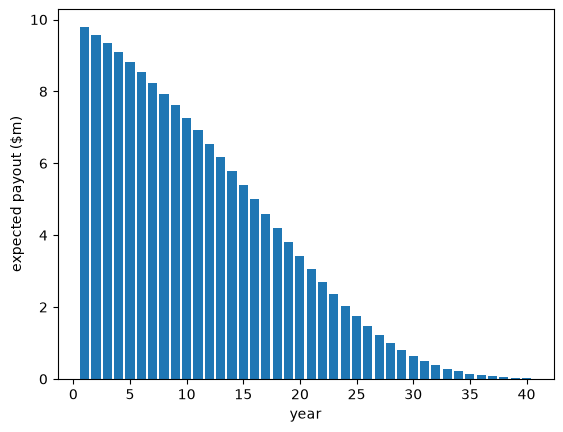

In [2]:
T = 40
qx = liabilities.gompertz_qx()
ages = np.random.default_rng(0).integers(65, 76, size=1000)
L = liabilities.annuity_cashflows(qx, ages, payment=0.01, horizon=T)
pv, D_L = liabilities.pv_duration(L, rate=0.04)
print(f"PV {pv:.1f}m, modified duration {D_L:.2f}")

plt.bar(range(1, T + 1), L)
plt.xlabel("year")
plt.ylabel("expected payout ($m)")
plt.show()

## Assets
Synthetic par bonds: Treasuries 1 to 30y, plus AAA/AA/A/BBB corporates. Net yield = ytm - expected default loss. Capital is limited by a cap, not charged for.

In [3]:
u = assets.synthetic_universe()
y = assets.net_yield(u)
C = assets.cashflow_matrix(u, T)
k = assets.capital_factor(u)
u.assign(net_yield=y).groupby("rating")[["ytm", "net_yield"]].mean().round(4)

,ytm,net_yield
rating,,
A,0.0581,0.0559
AA,0.0551,0.0540
AAA,0.0531,0.0526
BBB,0.0641,0.0597
UST,0.0518,0.0518


## Deterministic LP
Assets A = 102% of the liability PV. Which constraints bind, and what do they cost in yield?

In [4]:
A = 1.02 * pv
limits = dict(
    r=0.03, delta=0.5, max_weight=0.10, rating_caps={"BBB": 0.25}, capital_cap=0.02 * A
)


def solve(**kw):
    args = dict(
        y=y.to_numpy(),
        price=u.price.to_numpy(),
        C=C,
        L=L,
        dur=u.mod_dur.to_numpy(),
        D_L=D_L,
        A=A,
        k=k.to_numpy(),
        rating=u.rating.to_numpy(),
        **limits,
    )
    args.update(kw)
    return optimize.solve_deterministic(**args)


res = solve()
print(res.status, f"net yield {res.net_yield:.4f}")
pd.Series(res.duals, name="income per $ of slack").round(4)

optimal net yield 0.0597


budget           0.0543
cash_matching   -0.0041
duration_hi      0.0014
duration_lo      0.0000
issuer           0.0111
capital          0.1934
rating_BBB       0.0002
Name: income per $ of slack, dtype: float64

Check: the dual on capital should predict the income gained from a small relaxation.

In [5]:
step = 1e-4 * A
res2 = solve(capital_cap=limits["capital_cap"] + step)
print(
    f"predicted {res.duals['capital'] * step:.5f}, actual {(res2.net_yield - res.net_yield) * A:.5f}"
)

predicted 0.00211, actual 0.00211


Portfolio, as share of A.

In [6]:
(pd.Series(res.x * u.price.to_numpy(), index=u.name) / A).loc[lambda s: s > 1e-6].round(
    3
)

name
UST1     0.028
AAA30    0.100
AA2      0.027
AA3      0.053
AA5      0.100
AA20     0.014
AA30     0.100
A3       0.028
A5       0.100
A20      0.100
A30      0.100
BBB15    0.050
BBB20    0.100
BBB30    0.100
dtype: float64